# Exploración de datos: adiciones en contratos de obra pública (SECOP II)

**Pregunta de negocio.** ¿Qué contratos de obra pública firmados en SECOP II
tienen mayor probabilidad de recibir adiciones en tiempo o en valor durante su
ejecución, usando solo información disponible al momento de la firma, para que
la DIARI y las veedurías prioricen su seguimiento preventivo?

**Alcance.**

1. Unidad de análisis: contrato tipo "Obra" en SECOP II.
2. Cobertura: todo el país y todas las entidades; contratos firmados entre el
   1 de enero de 2019 y el 31 de diciembre de 2025.
3. Variable objetivo: `y = 1` si el contrato registra adición en valor (tabla
   Adiciones) o en tiempo (`dias_adicionados > 0`); `y = 0` en otro caso.
4. Variables explicativas: solo información disponible al firmar.

**Fuentes.** Conjuntos abiertos de SECOP II en datos.gov.co, descargados con
`src/ingest.py` el 7 de noviembre de 2026 y versionados con DVC:

1. Contratos Electrónicos (jbjy-vk9h): universo de contratos y adición en
   tiempo.
2. Procesos de Contratación (p6dx-8zbt): precio base, plazo publicado,
   valor adjudicado y respuestas al proceso.
3. Ofertas por Proceso (wi7w-2nvm): ofertas por proceso; solo cubre 2025 en
   adelante.
4. Garantías (gjp9-cutm): pólizas del contrato.
5. Proveedores Registrados (qmzu-gj57): características del contratista.
6. Adiciones (cb9c-h8sn): adición en valor.

**Secuencia del análisis.**

1. Carga y cobertura de los cruces.
2. Variable objetivo.
3. Calidad de los datos y valores pactados al firmar.
4. Estado del contrato y desenlace observable.
5. Datos faltantes en variables de firma.
6. Departamento.
7. Modalidad de contratación.
8. Valor y plazo pactados.
9. Mes de firma.
10. Entidades.
11. Adición en tiempo frente a adición en valor.
12. Proveedor y competencia.
13. Garantías.
14. Fuga de información.
15. Conclusiones para el modelado.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

RAW = Path("../data/raw")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
FECHA_DESCARGA = pd.Timestamp("2026-11-07")
MIN_DEP, MIN_ENT = 50, 30
UNIDADES = {"D": 1, "S": 7, "M": 30, "A": 365, "H": 1 / 24}
NO_DEFINIDO = {"", "nan", "no definido", "no definida", "no aplica",
               "sin descripcion"}

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format


def fecha(serie):
    """Convierte fechas de SECOP a datetime; las inválidas quedan en NaT."""
    return pd.to_datetime(serie.astype(str).str[:19], errors="coerce",
                          format="ISO8601")


def numero(serie):
    return pd.to_numeric(serie, errors="coerce")


def dias(cantidad, unidad):
    """Convierte una duración con unidad en texto (Dia(s), Mes(es)) a días."""
    return numero(cantidad) * unidad.str.strip().str[0].str.upper().map(
        UNIDADES)


def falta(serie):
    """Marca valores nulos o con texto equivalente a "no definido"."""
    texto = serie.astype(str).str.strip().str.lower()
    return serie.isna() | texto.isin(NO_DEFINIDO)


def tasas(df, por, minimo=0):
    """Contratos y tasa de adición total, en valor y en tiempo por grupo."""
    t = df.groupby(por, observed=True).agg(
        contratos=("y", "size"), y=("y", "mean"),
        valor=("y_valor", "mean"), tiempo=("y_tiempo", "mean"),
    )
    return t[t["contratos"] >= minimo]


def spearman(df, a, b):
    return df[[a, b]].corr("spearman").iloc[0, 1]


def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150)
    plt.show()

## 1. Carga y cobertura de los cruces

1. Se cargan las seis tablas.
2. Procesos se reduce a una fila por proceso de compra, priorizando la fase
   adjudicada y la publicación más reciente.
3. Se cruzan Procesos y Ofertas por `proceso_de_compra`, Proveedores por
   `codigo_proveedor`, y Adiciones y Garantías por `id_contrato`.
4. Se mide qué proporción de contratos encuentra pareja en cada tabla.

In [2]:
contratos = pd.read_csv(RAW / "contratos_obra.csv", low_memory=False,
                        dtype={"codigo_proveedor": str})
adiciones = pd.read_csv(RAW / "adiciones_valor.csv")
procesos = pd.read_csv(RAW / "procesos_obra.csv", low_memory=False)
ofertas = pd.read_csv(RAW / "ofertas_obra.csv")
garantias = pd.read_csv(RAW / "garantias_obra.csv")
proveedores = pd.read_csv(RAW / "proveedores_obra.csv", low_memory=False,
                          dtype={"codigo": str})

tablas = {"Contratos": contratos, "Adiciones": adiciones,
          "Procesos": procesos, "Ofertas": ofertas, "Garantías": garantias,
          "Proveedores": proveedores}
pd.DataFrame({n: t.shape for n, t in tablas.items()},
             index=["filas", "columnas"]).T

,filas,columnas
Contratos,40621,49
Adiciones,5240,4
Procesos,82821,16
Ofertas,6477,2
Garantías,1953,7
Proveedores,11380,11


In [3]:
duplicados = contratos["id_contrato"].duplicated().sum()
print(f"id_contrato duplicados: {duplicados}")
contratos = contratos.drop_duplicates("id_contrato")

procesos["adjudicado_si"] = procesos["adjudicado"].eq("Si")
procesos["publicacion"] = fecha(procesos["fecha_de_publicacion_del"])
proc = (procesos.sort_values(["adjudicado_si", "publicacion"],
                             ascending=False)
        .drop_duplicates("id_del_portafolio"))
prov = proveedores.drop_duplicates("codigo").add_prefix("prov_")

df = (contratos
      .merge(proc, how="left", left_on="proceso_de_compra",
             right_on="id_del_portafolio", validate="m:1")
      .merge(prov, how="left", left_on="codigo_proveedor",
             right_on="prov_codigo", validate="m:1")
      .merge(ofertas, how="left", left_on="proceso_de_compra",
             right_on="id_del_proceso_de_compra", validate="m:1"))
df["firma"] = fecha(df["fecha_de_firma"])
df["anio"] = df["firma"].dt.year
df["mes"] = df["firma"].dt.month

cobertura = pd.Series({
    "Procesos": df["id_del_portafolio"].notna().mean(),
    "Proveedores": df["prov_codigo"].notna().mean(),
    "Ofertas (firmados en 2025)":
        df.loc[df["anio"] == 2025, "n_ofertas"].notna().mean(),
    "Garantías": df["id_contrato"].isin(garantias["id_contrato"]).mean(),
})
print(f"Contratos de obra 2019-2025: {len(df):,}")
print((cobertura * 100).round(1).rename("% de contratos").to_string())
print("\nTipo de documento de los contratistas sin registro en Proveedores:")
print(df.loc[df["prov_codigo"].isna(), "tipodocproveedor"]
      .value_counts().to_string())

id_contrato duplicados: 0


Contratos de obra 2019-2025: 40,621
Procesos                     100.000
Proveedores                   66.600
Ofertas (firmados en 2025)    69.200
Garantías                      1.100

Tipo de documento de los contratistas sin registro en Proveedores:
tipodocproveedor
NIT                                10752
No Definido                         2005
Otro                                 584
Cédula de Ciudadanía                 218
Permiso especial de permanencia        1
Tarjeta de Identidad                   1
Cédula de Extranjería                  1


**Hallazgos.**

1. El universo tiene 40.621 contratos de obra firmados entre 2019 y 2025, sin `id_contrato` duplicados.
2. Todos los contratos encuentran su proceso en Procesos de Contratación.
3. Proveedores Registrados cubre el 66,6 % de los contratos. Los faltantes son sobre todo personas jurídicas (NIT), por lo que el vacío no se explica por personas naturales sin registro.
4. Ofertas por Proceso cubre el 69,2 % de los contratos firmados en 2025; la tabla no tiene datos anteriores.
5. Garantías cubre el 1,1 % de los contratos: la tabla publicada hoy tiene 48.949 pólizas en total.

## 2. Variable objetivo

1. `y_valor = 1` si el contrato aparece en Adiciones con tipo "Adicion en el
   valor".
2. `y_tiempo = 1` si `dias_adicionados > 0` en Contratos Electrónicos.
3. `y = 1` si ocurre cualquiera de las dos.
4. Se revisa el balance de clases y su estabilidad por año de firma, en total
   y dentro de las modalidades más frecuentes.

In [4]:
df["dias_adic"] = numero(df["dias_adicionados"]).fillna(0)
df["y_valor"] = df["id_contrato"].isin(adiciones["id_contrato"]).astype(int)
df["y_tiempo"] = (df["dias_adic"] > 0).astype(int)
df["y"] = df[["y_valor", "y_tiempo"]].max(axis=1)
print(f"Tasa y = {df['y'].mean():.1%} | valor = {df['y_valor'].mean():.1%}"
      f" | tiempo = {df['y_tiempo'].mean():.1%}")

por_anio = tasas(df, "anio")
print(por_anio.to_string())

principales = df["modalidad_de_contratacion"].value_counts().index[:4]
print("\nTasa de adición en tiempo por año y modalidad:")
print(df[df["modalidad_de_contratacion"].isin(principales)]
      .pivot_table(index="anio", columns="modalidad_de_contratacion",
                   values="y_tiempo", aggfunc="mean").to_string())

Tasa y = 36.4% | valor = 10.5% | tiempo = 28.3%
      contratos     y  valor  tiempo
anio                                
2019       2292 0.353  0.242   0.135
2020       2763 0.346  0.177   0.201
2021       5401 0.346  0.110   0.261
2022       5960 0.338  0.106   0.252
2023       7965 0.297  0.089   0.227
2024       6502 0.349  0.087   0.280
2025       9738 0.463  0.076   0.419

Tasa de adición en tiempo por año y modalidad:
modalidad_de_contratacion  Contratación directa  Licitación pública Obra Publica  Mínima cuantía  Selección Abreviada de Menor Cuantía
anio                                                                                                                                  
2019                                      0.000                            0.235           0.036                                 0.141
2020                                      0.270                            0.210           0.134                                 0.170
2021                           

**Hallazgos.**

1. La tasa global es 36,4 %: 10,5 % con adición en valor y 28,3 % con adición en tiempo. El desbalance es moderado.
2. La tasa total es estable entre 2019 y 2024 (29,7 % a 35,3 %) y sube a 46,3 % en 2025.
3. Las dos componentes se mueven en sentido contrario: la adición en valor baja de 24,2 % (2019) a 7,6 % (2025) y la adición en tiempo sube de 13,5 % a 41,9 %.
4. El aumento de la adición en tiempo ocurre dentro de cada modalidad (licitación pública: 23,5 % en 2019 y 67,0 % en 2025), y la contratación directa no registra días adicionados en 2019. Esto apunta a un cambio en la práctica de registro de `dias_adicionados`, no solo a un cambio en el riesgo.

## 3. Calidad de los datos y valores pactados al firmar

1. Se cuentan valores imposibles o atípicos en valor, plazo, fechas y días
   adicionados.
2. Se verifica si el valor, la duración y la fecha de fin publicados en
   Contratos Electrónicos se actualizan con las adiciones. Para ello se
   comparan con el valor adjudicado y el plazo publicado en Procesos, que se
   fijan antes de la firma.
3. Con base en lo anterior se definen `valor_inicial` (precio base del
   proceso) y `plazo_inicial` (duración publicada del proceso).

In [5]:
df["valor_actual"] = numero(df["valor_del_contrato"])
duracion = df["duraci_n_del_contrato"].str.extract(r"(\d+)\s*(\w+)")
df["plazo_contrato"] = dias(duracion[0], duracion[1])
df["inicio"] = fecha(df["fecha_de_inicio_del_contrato"])
df["fin"] = fecha(df["fecha_de_fin_del_contrato"])
precio_base = numero(df["precio_base"])
df["valor_inicial"] = precio_base.where(precio_base > 0)
plazo = dias(df["duracion"], df["unidad_de_duracion"].astype(str))
df["plazo_inicial"] = plazo.where(plazo.between(1, 3650))

chequeos = pd.Series({
    "Precio base nulo o 0": df["valor_inicial"].isna().sum(),
    "Plazo del proceso nulo, 0 o > 10 años":
        df["plazo_inicial"].isna().sum(),
    "Duración del contrato sin número": df["plazo_contrato"].isna().sum(),
    "Sin fecha de inicio": df["inicio"].isna().sum(),
    "Fin anterior a la firma": (df["fin"] < df["firma"]).sum(),
    "Días adicionados > 5 años": (df["dias_adic"] > 1825).sum(),
})
print(pd.DataFrame({"contratos": chequeos,
                    "%": chequeos / len(df) * 100}).round(2).to_string())
print("\nValor inicial (COP):")
print(df["valor_inicial"].describe(percentiles=[.01, .5, .99, .999])
      .to_string())

                                       contratos     %
Precio base nulo o 0                         101 0.250
Plazo del proceso nulo, 0 o > 10 años       3894 9.590
Duración del contrato sin número            2880 7.090
Sin fecha de inicio                          721 1.770
Fin anterior a la firma                      283 0.700
Días adicionados > 5 años                      4 0.010

Valor inicial (COP):
count               40,520.000
mean         5,215,240,951.155
std         85,849,673,486.999
min                      1.000
1%               6,000,000.000
50%            209,482,743.500
99%         64,376,283,697.000
99.9%      735,974,936,962.000
max     13,212,285,859,000.000


In [6]:
proceso_unico = ~df["proceso_de_compra"].duplicated(keep=False)
adjudicado = numero(df["valor_total_adjudicacion"])
df["valor_sobre_adjudicado"] = (df["valor_actual"] / adjudicado).where(
    (adjudicado > 0) & proceso_unico)
df["exceso_plazo"] = df["plazo_contrato"] - df["plazo_inicial"]
df["exceso_fechas"] = ((df["fin"] - df["inicio"]).dt.days
                       - df["plazo_inicial"])


def comparar(variable, grupo, umbral):
    datos = df[df[variable].notna()]
    return datos.groupby(grupo)[variable].agg(
        contratos="size", mediana="median",
        p90=lambda s: s.quantile(0.9),
        sobre_umbral=lambda s: (s > umbral).mean())


print("Valor actual / valor adjudicado (procesos de un solo contrato):")
print(comparar("valor_sobre_adjudicado", "y_valor", 1.05).to_string())
print("\nDuración del contrato - plazo del proceso (días):")
print(comparar("exceso_plazo", "y_tiempo", 15).to_string())
print("\n(Fin - inicio) - plazo del proceso (días):")
print(comparar("exceso_fechas", "y_tiempo", 15).to_string())

Valor actual / valor adjudicado (procesos de un solo contrato):
         contratos  mediana   p90  sobre_umbral
y_valor                                        
0            23396    1.000 1.458         0.290
1             3434    1.288 1.500         0.860

Duración del contrato - plazo del proceso (días):


          contratos  mediana     p90  sobre_umbral
y_tiempo                                          
0             24074    0.000  54.000         0.159
1              9842   24.000 210.000         0.524

(Fin - inicio) - plazo del proceso (días):
          contratos  mediana     p90  sobre_umbral
y_tiempo                                          
0             25859    1.000 169.000         0.301
1             10240   97.000 446.000         0.869


**Hallazgos.**

1. Los problemas de calidad son acotados: 0,25 % sin precio base, 9,6 % sin plazo del proceso válido, 1,8 % sin fecha de inicio y 0,7 % con fin anterior a la firma.
2. El precio base tiene una cola extrema (máximo de 1,3 · 10¹³ COP frente a una mediana de 209 millones), por lo que conviene usarlo en escala logarítmica.
3. `valor_del_contrato` incluye las adiciones: en procesos de un solo contrato, los contratos con adición en valor tienen una razón mediana de 1,29 frente al valor adjudicado y un percentil 90 de 1,50, igual al tope legal del 50 % (Ley 80 de 1993, art. 40). Sin adición la mediana es 1,00.
4. `duraci_n_del_contrato` también se actualiza: supera el plazo del proceso en más de 15 días en el 52,4 % de los contratos con adición en tiempo y en el 15,9 % de los demás.
5. `fecha_de_fin_del_contrato` incorpora las prórrogas: el exceso de (fin - inicio) sobre el plazo del proceso tiene mediana de 97 días con adición en tiempo y de 1 día sin ella.
6. En consecuencia, el valor y el plazo al firmar se toman de Procesos: `valor_inicial` es el precio base y `plazo_inicial` la duración publicada.
7. El 29,0 % de los contratos sin registro en Adiciones también supera en más de 5 % su valor adjudicado. Esto sugiere adiciones en valor no registradas como tal, es decir, subregistro en `y_valor`.

## 4. Estado del contrato y desenlace observable

1. Se compara la tasa de adición por estado del contrato.
2. Se mide el efecto de filtrar por estado (terminado o cerrado), como propone
   el alcance.
3. Se evalúa un criterio que no depende del desenlace: que el plazo inicial
   haya vencido antes de la fecha de descarga.

In [7]:
print(tasas(df, "estado_contrato")
      .sort_values("contratos", ascending=False).to_string())

terminados = df["estado_contrato"].str.lower().isin(["terminado", "cerrado"])
print(f"\nFiltro por estado (terminado o cerrado): {terminados.sum():,} "
      f"contratos, tasa {df.loc[terminados, 'y'].mean():.1%} frente a "
      f"{df['y'].mean():.1%} en el total.")

fin_pactado = df["inicio"].fillna(df["firma"]) + pd.to_timedelta(
    df["plazo_inicial"], unit="D")
df["vencido"] = (fin_pactado < FECHA_DESCARGA).astype(float).where(
    fin_pactado.notna())
vencidos = tasas(df, ["anio", "vencido"])["y"].unstack().rename(
    columns={0.0: "plazo vigente", 1.0: "plazo vencido"})
vencidos["% vencidos"] = df.groupby("anio")["vencido"].mean() * 100
sin_plazo = df["vencido"].isna().groupby(df["anio"]).mean()
vencidos["% sin plazo"] = sin_plazo * 100
print("\nTasa y por año según si el plazo inicial ya venció:")
print(vencidos.to_string())

                 contratos     y  valor  tiempo
estado_contrato                                
Modificado           14021 0.806  0.135   0.733
terminado            13503 0.172  0.127   0.050
En ejecución          7666 0.032  0.017   0.016
Cerrado               3414 0.158  0.142   0.019
Aprobado              1354 0.035  0.024   0.011
Suspendido             628 0.541  0.057   0.510
cedido                  35 0.171  0.029   0.143

Filtro por estado (terminado o cerrado): 16,917 contratos, tasa 16.9% frente a 36.4% en el total.

Tasa y por año según si el plazo inicial ya venció:
vencido  plazo vigente  plazo vencido  % vencidos  % sin plazo
anio                                                          
2019             1.000          0.352      99.955        2.269
2020             0.500          0.347      99.766        7.311
2021             0.000          0.340      99.838        8.424
2022             0.167          0.339      99.889        9.044
2023             0.190          0.292 

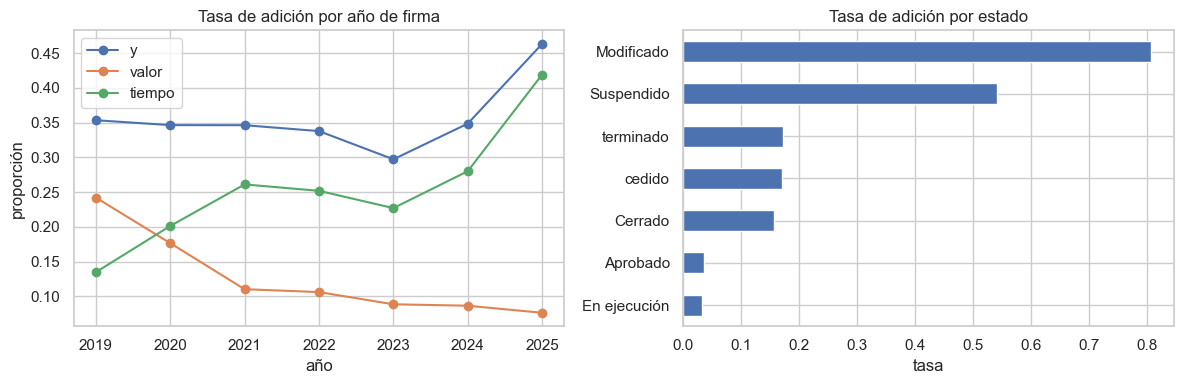

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_anio[["y", "valor", "tiempo"]].plot(marker="o", ax=ax[0])
ax[0].set(title="Tasa de adición por año de firma", xlabel="año",
          ylabel="proporción")
estados = tasas(df, "estado_contrato").sort_values("y")
estados["y"].plot.barh(ax=ax[1], title="Tasa de adición por estado")
ax[1].set(xlabel="tasa", ylabel="")
guardar_figura("01_tasa_anio_estado")

**Hallazgos.**

1. El estado depende del desenlace: "Modificado" tiene 80,6 % de adición y "En ejecución" 3,2 %.
2. Filtrar por estado terminado o cerrado, como propone el alcance, deja 16.917 contratos con una tasa de 16,9 % frente a 36,4 % del total. El filtro excluye justamente los contratos modificados y sesga la muestra.
3. Con el plazo inicial, más del 99 % de los contratos de 2019 a 2024 y el 95,7 % de los de 2025 ya debían haber terminado al momento de la descarga. La censura por contratos aún vigentes es pequeña y se concentra en 2025.
4. La muestra se define por fecha de firma y no por estado; solo se excluyen los contratos cuyo plazo inicial sigue vigente.

## 5. Datos faltantes en variables de firma

1. Se calcula la proporción de nulos o "No definido" en las variables que
   el formulario del tablero pediría al firmar.
2. Las variables de Ofertas solo se evalúan en contratos firmados en 2025.

modalidad_de_contratacion      0.000
orden                          0.000
origen_de_los_recursos         0.000
es_pyme                        0.000
justificacion_modalidad_de     0.000
respuestas_al_procedimiento    0.000
destino_gasto                  0.200
valor_inicial                  0.200
departamento                   2.400
tipodocproveedor               4.900
habilita_pago_adelantado       7.400
plazo_inicial                  9.600
valor adjudicado              28.300
n_ofertas (2025)              30.800
prov_tipo_empresa             33.400
prov_fecha_creacion           33.400
condiciones_de_entrega        36.200
prov_tama_o_entidad           62.300


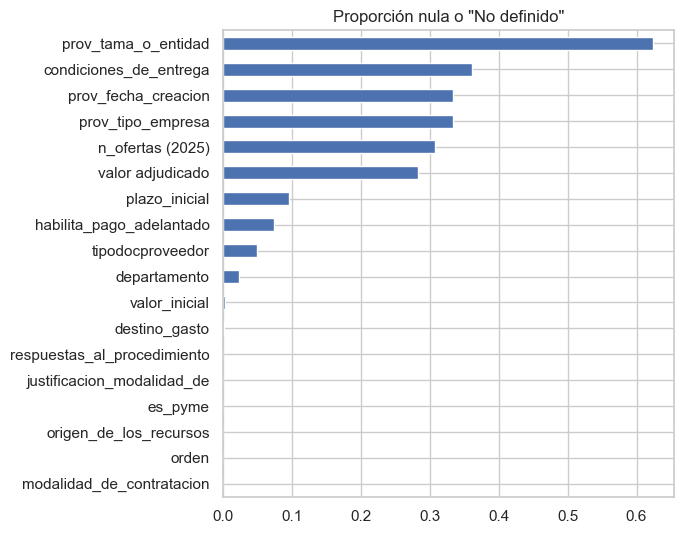

In [9]:
variables_firma = [
    "valor_inicial", "plazo_inicial", "modalidad_de_contratacion",
    "departamento", "orden", "origen_de_los_recursos", "destino_gasto",
    "condiciones_de_entrega", "tipodocproveedor", "es_pyme",
    "habilita_pago_adelantado", "justificacion_modalidad_de",
    "respuestas_al_procedimiento", "prov_fecha_creacion",
    "prov_tipo_empresa", "prov_tama_o_entidad",
]
faltantes = pd.Series({v: falta(df[v]).mean() for v in variables_firma})
faltantes["valor adjudicado"] = (~(adjudicado > 0)).mean()
faltantes["n_ofertas (2025)"] = df.loc[df["anio"] == 2025,
                                       "n_ofertas"].isna().mean()
faltantes = faltantes.sort_values()
print((faltantes * 100).round(1).rename("% faltante").to_string())

faltantes.plot.barh(figsize=(7, 5.5),
                    title="Proporción nula o \"No definido\"")
guardar_figura("02_faltantes")

**Hallazgos.**

1. Modalidad, orden, origen de los recursos, justificación de la modalidad y respuestas al proceso no tienen faltantes.
2. Valor inicial (0,2 %), departamento (2,4 %) y tipo de documento del proveedor (4,9 %) tienen pocos faltantes.
3. Plazo inicial (9,6 %) y pago adelantado (7,4 %) requieren imputación con indicador de faltante.
4. Valor adjudicado falta en el 28,3 %, casi todo en contratación directa y régimen especial, donde no hay adjudicación.
5. Condiciones de entrega (36,2 %), datos del proveedor (33,4 %) y tamaño de la empresa (62,3 %) son opcionales en el formulario.

## 6. Departamento

1. Se calcula la tasa por departamento de la entidad con al menos `MIN_DEP`
   contratos.
2. Se mide la concentración de contratos por departamento.

Departamentos con n >= 50: 31. Tasa entre 18.5% y 50.6%.
              contratos     y  valor  tiempo
departamento                                
Chocó               405 0.185  0.040   0.158
Casanare            570 0.196  0.074   0.135
Caquetá             547 0.203  0.090   0.126
La Guajira          359 0.245  0.053   0.214
Putumayo            470 0.281  0.049   0.247
                                          contratos     y  valor  tiempo
departamento                                                            
Quindío                                         508 0.445  0.096   0.372
Sucre                                           310 0.445  0.090   0.387
Risaralda                                       699 0.454  0.084   0.386
Magdalena                                       588 0.463  0.048   0.429
San Andrés, Providencia y Santa Catalina         85 0.506  0.224   0.341

Departamentos con más contratos:
                            contratos     y  valor  tiempo  % contratos
departament

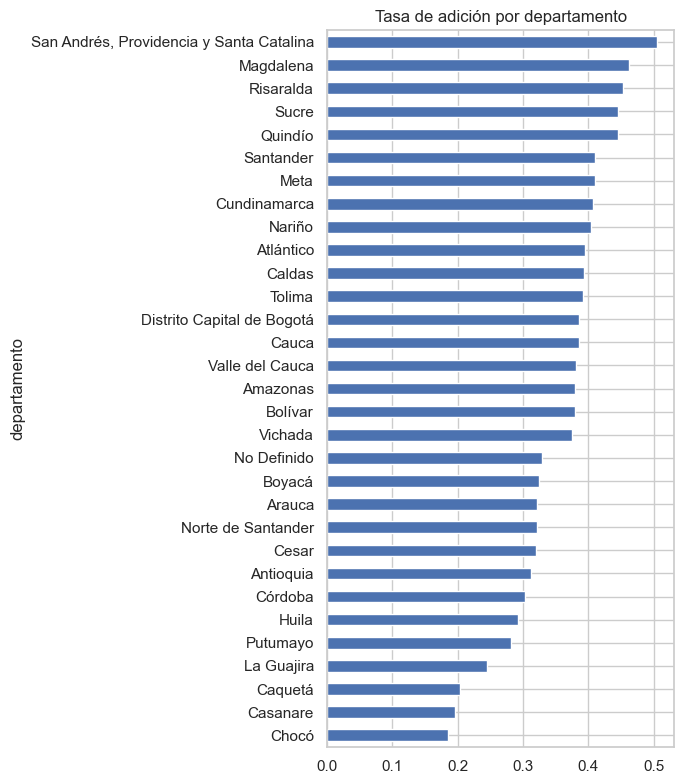

In [10]:
dep = tasas(df, "departamento", MIN_DEP).sort_values("y")
print(f"Departamentos con n >= {MIN_DEP}: {len(dep)}. Tasa entre "
      f"{dep['y'].min():.1%} y {dep['y'].max():.1%}.")
print(dep.head(5).to_string())
print(dep.tail(5).to_string())
mayores = dep.nlargest(5, "contratos")
mayores["% contratos"] = mayores["contratos"] / len(df) * 100
print("\nDepartamentos con más contratos:")
print(mayores.to_string())

dep["y"].plot.barh(figsize=(7, 8), title="Tasa de adición por departamento")
guardar_figura("03_departamento")

**Hallazgos.**

1. Treinta y un departamentos tienen al menos 50 contratos; su tasa va de 18,5 % (Chocó) a 50,6 % (San Andrés).
2. Bogotá concentra el 28,7 % de los contratos con una tasa de 38,6 %, cercana a la global; Antioquia, el 11,1 % con 31,3 %.
3. La variación entre departamentos es amplia pero menor que entre entidades, por lo que el departamento aporta contexto territorial más que poder predictivo propio.

## 7. Modalidad de contratación

1. Se calcula la tasa total, en valor y en tiempo por modalidad.
2. Se identifican modalidades con pocos contratos para agruparlas.

                                                             contratos     y  valor  tiempo
modalidad_de_contratacion                                                                  
Selección Abreviada de Menor Cuantía                             11275 0.381  0.145   0.270
Contratación directa                                              8580 0.324  0.028   0.305
Mínima cuantía                                                    8003 0.261  0.136   0.142
Licitación pública Obra Publica                                   7533 0.518  0.124   0.430
Contratación régimen especial                                     2029 0.271  0.070   0.215
Contratación régimen especial (con ofertas)                       1419 0.407  0.078   0.353
Contratación Directa (con ofertas)                                1369 0.297  0.052   0.269
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes        257 0.486  0.152   0.381
Licitación pública                                                 156 0.397  0.

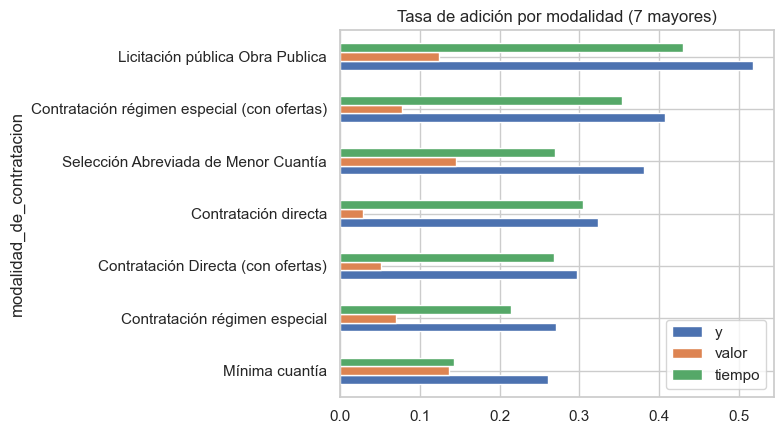

In [11]:
mod = tasas(df, "modalidad_de_contratacion").sort_values(
    "contratos", ascending=False)
print(mod.to_string())
print("Modalidades con menos de 1.000 contratos:",
      (mod["contratos"] < 1000).sum(), "de", len(mod))

mod.head(7)[["y", "valor", "tiempo"]].sort_values("y").plot.barh(
    figsize=(8, 4.5), title="Tasa de adición por modalidad (7 mayores)")
guardar_figura("04_modalidad")

**Hallazgos.**

1. La licitación pública de obra tiene la tasa más alta (51,8 %), seguida de selección abreviada de menor cuantía (38,1 %), contratación directa (32,4 %) y mínima cuantía (26,1 %).
2. Las modalidades difieren en el tipo de adición: la contratación directa casi no registra adición en valor (2,8 %) pero sí en tiempo (30,5 %); en mínima cuantía ambas son similares (13,6 % en valor y 14,2 % en tiempo).
3. Dos de nueve modalidades tienen menos de 1.000 contratos y son variantes de otras ("Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes" y "Licitación pública"), por lo que se agrupan con su modalidad principal.

## 8. Valor y plazo pactados

1. Se calcula la tasa por decil de valor inicial.
2. Se cruza el decil de valor con rangos de plazo inicial; se ocultan las
   celdas con menos de `MIN_ENT` contratos.
3. Se mide la correlación de Spearman de cada variable con `y`.

             contratos     y  valor  tiempo
decil_valor                                
1                 3663 0.149  0.070   0.085
2                 3663 0.244  0.091   0.167
3                 3663 0.301  0.114   0.201
4                 3663 0.261  0.073   0.200
5                 3663 0.367  0.111   0.284
6                 3663 0.360  0.121   0.264
7                 3663 0.414  0.121   0.324
8                 3663 0.459  0.120   0.370
9                 3663 0.523  0.129   0.434
10                3663 0.545  0.124   0.461

Spearman valor ~ y: 0.246 | plazo ~ y: 0.126 | valor ~ plazo: 0.593


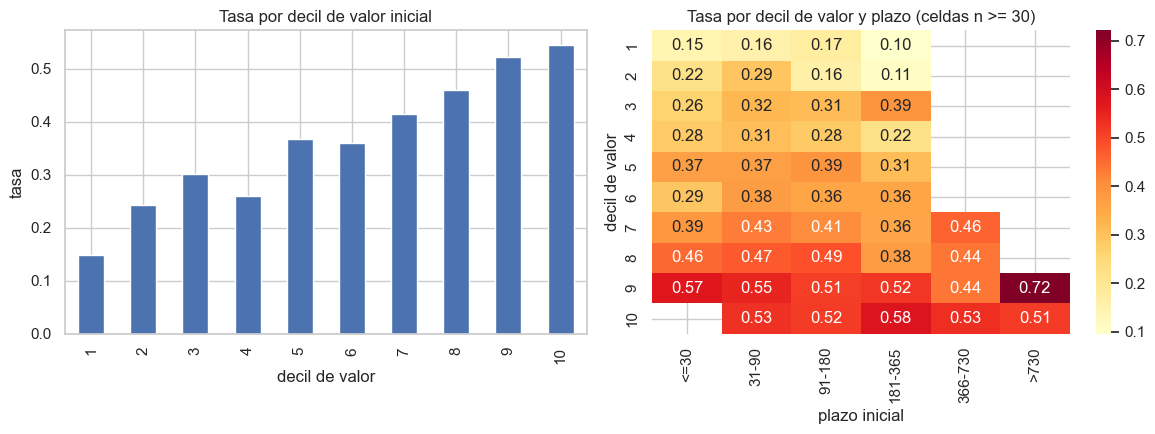

In [12]:
vp = df.dropna(subset=["valor_inicial", "plazo_inicial"]).copy()
vp["decil_valor"] = pd.qcut(vp["valor_inicial"], 10, labels=range(1, 11))
vp["rango_plazo"] = pd.cut(
    vp["plazo_inicial"], [0, 30, 90, 180, 365, 730, 3650],
    labels=["<=30", "31-90", "91-180", "181-365", "366-730", ">730"])
por_decil = tasas(vp, "decil_valor")
print(por_decil.to_string())
print(f"\nSpearman valor ~ y: {spearman(vp, 'valor_inicial', 'y'):.3f} | "
      f"plazo ~ y: {spearman(vp, 'plazo_inicial', 'y'):.3f} | "
      f"valor ~ plazo: "
      f"{spearman(vp, 'valor_inicial', 'plazo_inicial'):.3f}")

celdas = vp.pivot_table(index="decil_valor", columns="rango_plazo",
                        values="y", aggfunc=["mean", "size"], observed=True)
mapa = celdas["mean"].where(celdas["size"] >= MIN_ENT)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
por_decil["y"].plot.bar(ax=ax[0], title="Tasa por decil de valor inicial")
ax[0].set(xlabel="decil de valor", ylabel="tasa")
sns.heatmap(mapa, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[1])
ax[1].set(title=f"Tasa por decil de valor y plazo (celdas n >= {MIN_ENT})",
          xlabel="plazo inicial", ylabel="decil de valor")
guardar_figura("05_valor_plazo")

**Hallazgos.**

1. La tasa crece con el valor inicial: 14,9 % en el decil 1 y 54,5 % en el decil 10 (Spearman 0,25).
2. El plazo inicial tiene una relación más débil (Spearman 0,13) y está correlacionado con el valor (0,59), por lo que gran parte de su señal se comparte con el valor.
3. El crecimiento se explica sobre todo por la adición en tiempo (8,5 % a 46,1 %); la adición en valor varía menos entre deciles (7,0 % a 12,9 %).

## 9. Mes de firma

1. Se compara el volumen de firmas y la tasa de adición por mes.

mes            1       2         3         4         5         6         7         8         9         10        11        12
contratos 546.000 742.000 1,342.000 1,793.000 2,653.000 3,288.000 3,300.000 3,411.000 4,312.000 5,308.000 6,514.000 7,412.000
y           0.368   0.361     0.320     0.313     0.325     0.335     0.366     0.350     0.383     0.356     0.384     0.395
valor       0.158   0.139     0.102     0.119     0.123     0.120     0.126     0.127     0.111     0.104     0.086     0.079
tiempo      0.236   0.247     0.232     0.216     0.224     0.239     0.269     0.253     0.297     0.275     0.318     0.341


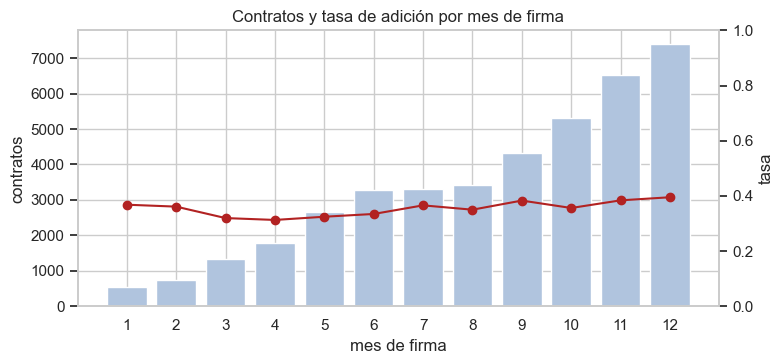

In [13]:
mes = tasas(df, "mes")
print(mes.T.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(mes.index, mes["contratos"], color="lightsteelblue")
ax.set(xticks=range(1, 13), xlabel="mes de firma", ylabel="contratos",
       title="Contratos y tasa de adición por mes de firma")
ax2 = ax.twinx()
ax2.plot(mes.index, mes["y"], color="firebrick", marker="o")
ax2.set(ylabel="tasa", ylim=(0, 1))
ax2.grid(False)
guardar_figura("06_mes")

**Hallazgos.**

1. El volumen de firmas crece a lo largo del año: diciembre concentra 7.412 contratos (18,2 %) frente a 546 en enero.
2. La tasa total varía poco (31,3 % a 39,5 %), pero sus componentes se separan: los contratos firmados en noviembre y diciembre tienen más adición en tiempo (31,8 % y 34,1 %) y menos en valor (8,6 % y 7,9 %) que los de enero (23,6 % y 15,8 %).
3. El mes de firma es útil como variable si se modela cada tipo de adición por separado.

## 10. Entidades

1. Se mide la concentración de contratos con adición por entidad.
2. Se describe la dispersión de la tasa entre entidades con al menos
   `MIN_ENT` contratos.

Entidades: 2,378. Las 10 mayores concentran 22.8% de los contratos con adición; las 100 mayores, 51.9%.
                                                              contratos  con_adicion     y
nombre_entidad                                                                            
INVIAS                                                             2725         1271 0.466
INSTITUTO DE CAMINOS Y CONSTRUCCIONES DE CUNDINAMARCA - ICCU       2577          760 0.295
AEROCIVIL                                                          1156          313 0.271
MUNICIPIO DE MANIZALES                                              403          231 0.573
AGENCIA PARA LA INFRAESTRUCTURA DEL META                            277          163 0.588
SECRETARIA DE EDUCACION DE CALI                                     174          155 0.891
MUNICIPIO DE BUCARAMANGA                                            182          138 0.758
GOBERNACION DEL MAGDALENA                                           255      

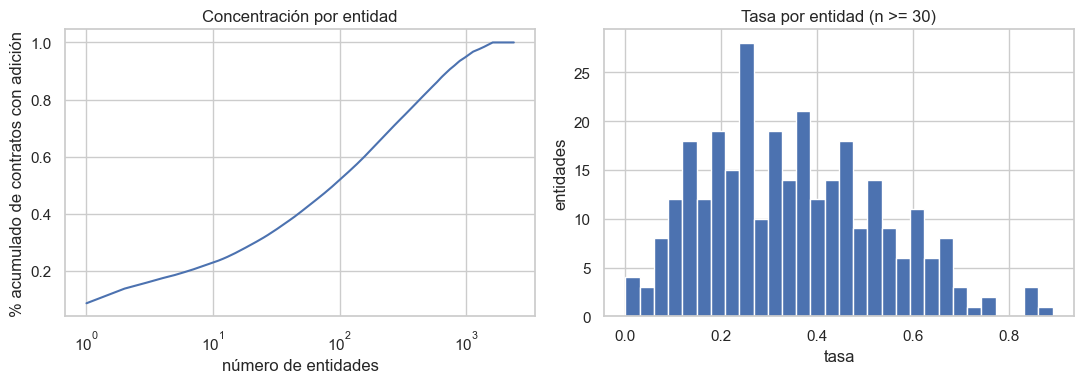

In [14]:
ent = df.groupby("nombre_entidad").agg(
    contratos=("y", "size"), con_adicion=("y", "sum"), y=("y", "mean"),
).sort_values("con_adicion", ascending=False)
acumulado = ent["con_adicion"].cumsum() / ent["con_adicion"].sum()
print(f"Entidades: {len(ent):,}. Las 10 mayores concentran "
      f"{acumulado.iloc[9]:.1%} de los contratos con adición; "
      f"las 100 mayores, {acumulado.iloc[99]:.1%}.")
print(ent.head(10).to_string())
grandes = ent[ent["contratos"] >= MIN_ENT]
print(f"Entidades con n >= {MIN_ENT}: {len(grandes)} "
      f"({grandes['contratos'].sum() / len(df):.1%} de los contratos). "
      f"Tasa p10, p50, p90: "
      f"{grandes['y'].quantile([.1, .5, .9]).round(3).tolist()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(ent) + 1), acumulado.values)
ax[0].set(xscale="log", xlabel="número de entidades",
          ylabel="% acumulado de contratos con adición",
          title="Concentración por entidad")
grandes["y"].hist(bins=30, ax=ax[1])
ax[1].set(title=f"Tasa por entidad (n >= {MIN_ENT})", xlabel="tasa",
          ylabel="entidades")
guardar_figura("07_entidades")

**Hallazgos.**

1. Hay 2.378 entidades; las 10 mayores concentran el 22,8 % de los contratos con adición y las 100 mayores el 51,9 %.
2. INVIAS es la entidad con más contratos (2.725) y una tasa de 46,6 %.
3. Entre las 300 entidades con al menos 30 contratos, que suman el 69,1 % del total, la tasa va de 12,7 % (p10) a 60,8 % (p90).
4. La entidad es la variable de firma más informativa, pero su alta cardinalidad exige codificación con suavizado y una evaluación con entidades no vistas.

## 11. Adición en tiempo frente a adición en valor

1. Se cruzan ambos tipos de adición.
2. Se comparan sus tasas por modalidad para decidir si conviene modelarlas por
   separado.

In [15]:
print(pd.crosstab(df["y_valor"], df["y_tiempo"], margins=True).to_string())
p_v_t = df.loc[df["y_tiempo"] == 1, "y_valor"].mean()
p_t_v = df.loc[df["y_valor"] == 1, "y_tiempo"].mean()
print(f"P(valor | tiempo) = {p_v_t:.3f} | P(tiempo | valor) = {p_t_v:.3f}")
print(mod.head(6)[["valor", "tiempo"]].to_string())

y_tiempo      0      1    All
y_valor                      
0         25827  10509  36336
1          3308    977   4285
All       29135  11486  40621
P(valor | tiempo) = 0.085 | P(tiempo | valor) = 0.228
                                             valor  tiempo
modalidad_de_contratacion                                 
Selección Abreviada de Menor Cuantía         0.145   0.270
Contratación directa                         0.028   0.305
Mínima cuantía                               0.136   0.142
Licitación pública Obra Publica              0.124   0.430
Contratación régimen especial                0.070   0.215
Contratación régimen especial (con ofertas)  0.078   0.353


**Hallazgos.**

1. Solo 977 contratos tienen ambos tipos de adición.
2. P(valor | tiempo) = 8,5 % y P(tiempo | valor) = 22,8 %: los dos desenlaces son casi independientes.
3. Los perfiles por modalidad son distintos, lo que respalda dos probabilidades separadas en el tablero (tiempo y valor) además de la combinada.

## 12. Proveedor y competencia

1. Antigüedad del proveedor en SECOP II al firmar (Proveedores Registrados).
2. Contratos de obra previos del mismo proveedor dentro del periodo, contados
   solo con firmas anteriores para no usar información futura.
3. Respuestas al proceso (Procesos) y su consistencia con el conteo de ofertas
   de 2025 (Ofertas por Proceso).
4. Razón entre el valor adjudicado y el precio base, que mide qué tan por
   debajo del presupuesto se adjudicó.

Proveedor registrado después de la firma: 0.5%

antiguedad_prov (cobertura 66.6%, Spearman con y 0.094)
             contratos     y  valor  tiempo
rango                                      
(-inf, 0.0]        381 0.218  0.042   0.189
(0.0, 1.0]        6274 0.272  0.088   0.197
(1.0, 3.0]        7672 0.317  0.130   0.211
(3.0, 5.0]        6777 0.336  0.129   0.231
(5.0, inf]        5955 0.391  0.109   0.310



previos_prov (cobertura 100.0%, Spearman con y -0.036)
             contratos     y  valor  tiempo
rango                                      
(-1.0, 0.0]      20885 0.383  0.105   0.304
(0.0, 2.0]        8547 0.342  0.117   0.247
(2.0, 9.0]        7020 0.354  0.110   0.270
(9.0, inf]        4169 0.335  0.079   0.273



respuestas (cobertura 100.0%, Spearman con y 0.114)
             contratos     y  valor  tiempo
rango                                      
(-1.0, 0.0]      11640 0.313  0.041   0.282
(0.0, 1.0]        8934 0.321  0.100   0.249
(1.0, 2.0]        3524 0.349  0.108   0.264
(2.0, 5.0]        5749 0.384  0.143   0.269
(5.0, 10.0]       4535 0.419  0.177   0.277
(10.0, inf]       6238 0.471  0.145   0.359

adjudicado_sobre_base (cobertura 71.7%, Spearman con y -0.061)
              contratos     y  valor  tiempo
rango                                       
(0.0, 0.8]         4529 0.406  0.180   0.253
(0.8, 0.9]         2374 0.353  0.192   0.187
(0.9, 0.95]        3001 0.457  0.135   0.355
(0.95, 0.99]       6520 0.414  0.133   0.314
(0.99, inf]       12684 0.343  0.099   0.270


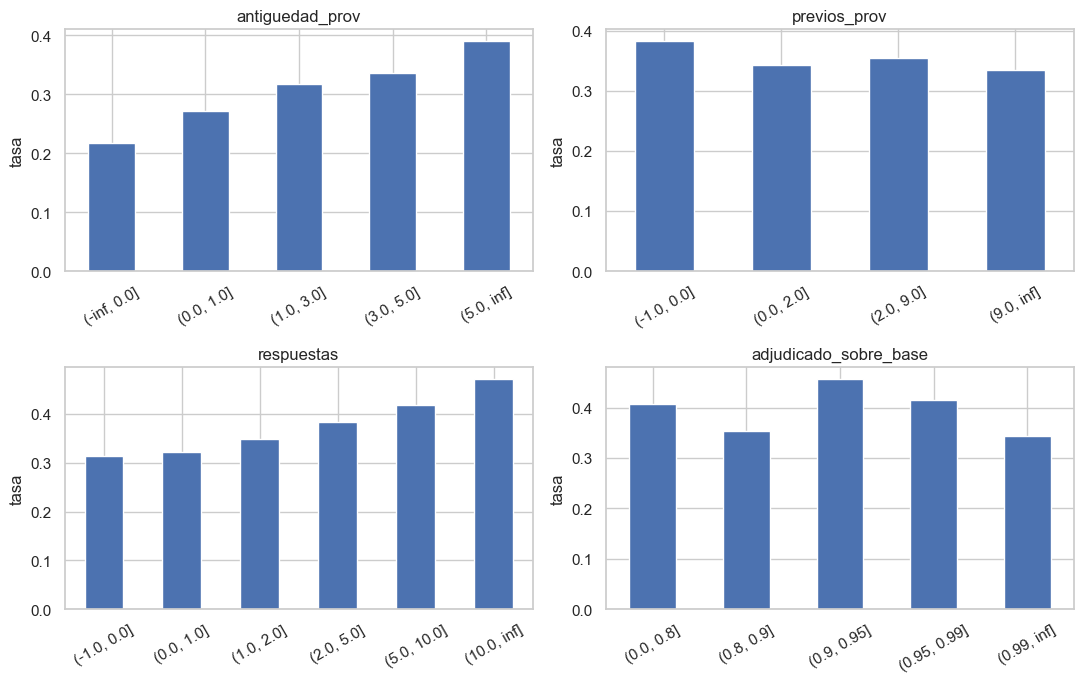


Tasa por condición de pyme y tipo de documento del proveedor:
             contratos     y  valor  tiempo
prov_espyme                                
NO                6601 0.299  0.054   0.257
SI               20458 0.335  0.134   0.227
                      contratos     y  valor  tiempo
tipodocproveedor                                    
Cédula de Ciudadanía       5579 0.329  0.135   0.221
NIT                       32203 0.362  0.099   0.286
No Definido                2005 0.476  0.115   0.397
Otro                        826 0.420  0.143   0.309

2025: Spearman respuestas ~ ofertas = 0.994; coinciden en 87.7% de 6,739 contratos.


In [16]:
df["antiguedad_prov"] = (df["firma"] - fecha(df["prov_fecha_creacion"])
                         ).dt.days / 365.25
df = df.sort_values("firma")
df["previos_prov"] = df.groupby("codigo_proveedor").cumcount()
df["respuestas"] = numero(df["respuestas_al_procedimiento"])
df["adjudicado_sobre_base"] = (
    numero(df["valor_total_adjudicacion"]) / df["valor_inicial"]
).where(numero(df["valor_total_adjudicacion"]) > 0)

print("Proveedor registrado después de la firma:",
      f"{(df['antiguedad_prov'] < 0).mean():.1%}")
grupos = {
    "antiguedad_prov": [-np.inf, 0, 1, 3, 5, np.inf],
    "previos_prov": [-1, 0, 2, 9, np.inf],
    "respuestas": [-1, 0, 1, 2, 5, 10, np.inf],
    "adjudicado_sobre_base": [0, 0.8, 0.9, 0.95, 0.99, np.inf],
}
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for eje, (var, cortes) in zip(ax.flat, grupos.items()):
    t = tasas(df.assign(rango=pd.cut(df[var], cortes)), "rango")
    print(f"\n{var} (cobertura {df[var].notna().mean():.1%}, Spearman "
          f"con y {spearman(df, var, 'y'):.3f})")
    print(t.to_string())
    t["y"].plot.bar(ax=eje, title=var, rot=30)
    eje.set(xlabel="", ylabel="tasa")
guardar_figura("08_proveedor_competencia")

print("\nTasa por condición de pyme y tipo de documento del proveedor:")
print(tasas(df, "prov_espyme").to_string())
print(tasas(df, "tipodocproveedor", MIN_ENT).to_string())

d25 = df[(df["anio"] == 2025) & df["n_ofertas"].notna()]
print(f"\n2025: Spearman respuestas ~ ofertas = "
      f"{spearman(d25, 'respuestas', 'n_ofertas'):.3f}; coinciden en "
      f"{(d25['respuestas'] == d25['n_ofertas']).mean():.1%} de "
      f"{len(d25):,} contratos.")

**Hallazgos.**

1. Los proveedores con más antigüedad en SECOP II tienen más adiciones: 27,2 % con un año o menos frente a 39,1 % con más de cinco años.
2. Los contratos previos del proveedor dentro del periodo no muestran relación (Spearman -0,04).
3. Más respuestas al proceso se asocian con más adiciones: 31,3 % sin respuestas y 47,1 % con más de 10. La relación probablemente refleja que los procesos competidos son de mayor valor.
4. Una adjudicación muy por debajo del precio base (razón de 0,8 o menos) casi duplica la tasa de adición en valor frente a adjudicar cerca del precio base (18,0 % y 9,9 %).
5. Las pymes tienen más adición en valor (13,4 %) que las no pymes (5,4 %).
6. `respuestas_al_procedimiento` de Procesos coincide con el conteo de Ofertas por Proceso en el 87,7 % de los contratos de 2025 (Spearman 0,994). Se usa Procesos porque cubre todo el periodo.

## 13. Garantías

1. Se mide la cobertura de la tabla de Garantías por año de firma.
2. Se compara la fecha de creación de las pólizas con la fecha de firma.

In [17]:
garantias["creacion"] = fecha(garantias["fechadecreacionpoliza"])
por_contrato = garantias.groupby("id_contrato").agg(
    n_polizas=("tipopoliza", "size"), primera_poliza=("creacion", "min"))
df = df.merge(por_contrato, how="left", left_on="id_contrato",
              right_index=True)
df["n_polizas"] = df["n_polizas"].fillna(0)
print("Cobertura de Garantías por año de firma (%):")
print((df["n_polizas"].gt(0).groupby(df["anio"]).mean() * 100)
      .round(1).to_string())

con_poliza = df[df["n_polizas"] > 0]
dias_a_poliza = (con_poliza["primera_poliza"] - con_poliza["firma"]).dt.days
print(f"\nContratos con póliza: {len(con_poliza):,}. Días entre la firma y "
      "la primera póliza:")
print(dias_a_poliza.describe(percentiles=[.1, .5, .9]).round(1).to_string())

Cobertura de Garantías por año de firma (%):
anio
2019   0.300
2020   0.700
2021   0.700
2022   0.500
2023   0.700
2024   0.700
2025   2.400

Contratos con póliza: 429. Días entre la firma y la primera póliza:
count     429.000
mean      457.600
std       457.400
min        -3.000
10%        33.800
50%       302.000
90%     1,050.400
max     2,428.000


**Hallazgos.**

1. La cobertura es menor al 2,5 % en todos los años.
2. La primera póliza registrada se crea, en mediana, 302 días después de la firma, por lo que la tabla refleja sobre todo pólizas de modificaciones y no las garantías pactadas al firmar.
3. Garantías no se usa como fuente de variables mientras la tabla siga incompleta.

## 14. Fuga de información

1. Se calcula el AUC de cada variable por sí sola frente a `y`.
2. Numéricas: AUC directo sobre los valores no nulos, tomando el máximo entre
   AUC y 1 - AUC.
3. Categóricas: tasa por categoría calculada fuera del pliegue (5 pliegues
   estratificados), para no premiar categorías raras.
4. Las variables se separan entre disponibles al firmar y posteriores a la
   firma. Una variable posterior con AUC alto confirma fuga; un AUC cercano a
   0,5 indica que la variable no aporta señal por sí sola.

                  variable   momento   auc
           estado_contrato posterior 0.864
             exceso_fechas posterior 0.760
    valor_sobre_adjudicado posterior 0.704
            nombre_entidad     firma 0.669
              valor_actual posterior 0.660
             valor_inicial     firma 0.646
            plazo_contrato posterior 0.646
 modalidad_de_contratacion     firma 0.601
justificacion_modalidad_de     firma 0.598
             plazo_inicial     firma 0.575
                respuestas     firma 0.567
               prov_espyme     firma 0.559
         prov_tipo_empresa     firma 0.558
           antiguedad_prov     firma 0.558
              departamento     firma 0.551
    condiciones_de_entrega     firma 0.542
         valor_facturado_n posterior 0.541
     adjudicado_sobre_base     firma 0.536
               saldo_cdp_n posterior 0.533
                ultima_act posterior 0.532
                       mes     firma 0.527
          tipodocproveedor     firma 0.520
           

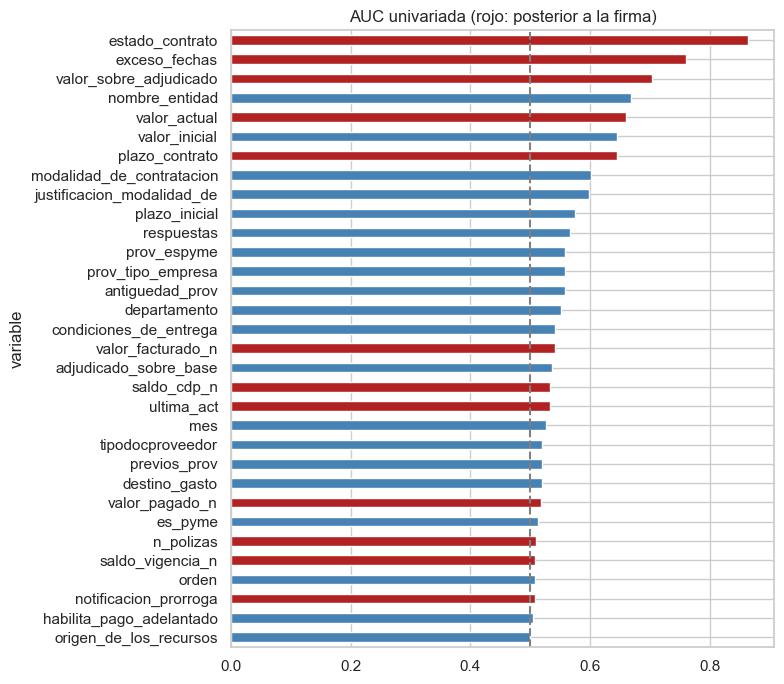

In [18]:
def auc_numerica(x, y):
    validos = x.notna()
    auc = roc_auc_score(y[validos], x[validos])
    return max(auc, 1 - auc)


def auc_categorica(x, y, pliegues=5):
    x = x.fillna("NA").astype(str).to_numpy()
    y = y.to_numpy()
    pred = np.zeros(len(y))
    cv = StratifiedKFold(pliegues, shuffle=True, random_state=42)
    for tr, te in cv.split(x, y):
        tasa = pd.Series(y[tr]).groupby(x[tr]).mean()
        pred[te] = pd.Series(x[te]).map(tasa).fillna(y[tr].mean())
    return roc_auc_score(y, pred)


df["ultima_act"] = (fecha(df["ultima_actualizacion"])
                    - pd.Timestamp("2019-01-01")).dt.days
df["notificacion_prorroga"] = df["fecha_de_notificaci_n_de_prorrogaci_n"
                                 ].notna().astype(int)
for v in ["valor_pagado", "valor_facturado", "saldo_cdp", "saldo_vigencia"]:
    df[v + "_n"] = numero(df[v])

firma_num = ["valor_inicial", "plazo_inicial", "mes", "respuestas",
             "adjudicado_sobre_base", "antiguedad_prov", "previos_prov"]
firma_cat = ["nombre_entidad", "modalidad_de_contratacion", "departamento",
             "orden", "origen_de_los_recursos", "destino_gasto",
             "tipodocproveedor", "es_pyme", "prov_espyme",
             "prov_tipo_empresa", "condiciones_de_entrega",
             "habilita_pago_adelantado", "justificacion_modalidad_de"]
posterior_num = ["valor_actual", "valor_sobre_adjudicado", "plazo_contrato",
                 "exceso_fechas", "valor_pagado_n", "valor_facturado_n",
                 "saldo_cdp_n", "saldo_vigencia_n", "ultima_act",
                 "n_polizas", "notificacion_prorroga"]
posterior_cat = ["estado_contrato"]

filas = (
    [(v, "firma", auc_numerica(df[v], df["y"])) for v in firma_num]
    + [(v, "firma", auc_categorica(df[v], df["y"])) for v in firma_cat]
    + [(v, "posterior", auc_numerica(df[v], df["y"]))
       for v in posterior_num]
    + [(v, "posterior", auc_categorica(df[v], df["y"]))
       for v in posterior_cat]
)
fuga = pd.DataFrame(filas, columns=["variable", "momento", "auc"])
fuga = fuga.sort_values("auc", ascending=False)
print(fuga.round(3).to_string(index=False))

colores = fuga["momento"].map({"firma": "steelblue",
                               "posterior": "firebrick"})
ax = fuga.plot.barh(x="variable", y="auc", color=colores, legend=False,
                    figsize=(8, 7), title="AUC univariada (rojo: posterior "
                    "a la firma)")
ax.axvline(0.5, color="gray", ls="--")
ax.invert_yaxis()
guardar_figura("09_fuga_auc")

**Hallazgos.**

1. `estado_contrato` es la variable con mayor AUC (0,86) y confirma la fuga identificada en la sección 4.
2. El exceso de la fecha de fin (0,76), el valor actual sobre el adjudicado (0,70), el valor actual (0,66) y la duración del contrato (0,65) son posteriores a la firma y se excluyen.
3. Las variables de ejecución restantes (pagos, facturación, saldos, última actualización, notificación de prórroga y pólizas) tienen AUC entre 0,50 y 0,54: no aportan señal y tampoco se usan.
4. Entre las variables de firma, las más informativas son la entidad (0,67), el valor inicial (0,65), la modalidad (0,60) y el plazo inicial (0,58). Ninguna variable de firma por sí sola supera 0,70, lo que descarta fuga en ellas.
5. El origen de los recursos (0,50), el orden (0,51) y el pago adelantado (0,50) no aportan señal por sí solos.

## 15. Conclusiones para el modelado

1. **Muestra.** Contratos de obra firmados entre 2019 y 2025 definidos por fecha de firma, sin filtrar por estado. Se excluyen solo los contratos con plazo inicial vigente.
2. **Variable objetivo.** Tasa de 36,4 %. Se entrenan un modelo combinado y dos por tipo de adición, porque tiempo y valor tienen perfiles distintos.
3. **Variables.** Valor inicial (logaritmo), plazo inicial, modalidad agrupada, departamento, entidad, mes de firma, respuestas al proceso, razón adjudicado sobre precio base, antigüedad del proveedor, condición de pyme y tipo de documento del proveedor, con indicadores de faltante.
4. **Exclusiones por fuga.** `estado_contrato`, `valor_del_contrato`, `duraci_n_del_contrato`, `fecha_de_fin_del_contrato`, `dias_adicionados` y todas las variables de ejecución.
5. **Partición temporal.** Entrenamiento 2019 a 2023, validación 2024 y prueba 2025. Por el cambio de registro de los días adicionados, se reportan métricas por año y se recalibra la probabilidad con el año más reciente.
6. **Entidad.** Codificación por tasa con suavizado calculada dentro de cada pliegue y evaluación adicional con entidades no vistas.
7. **Métricas.** PR-AUC y precisión en k como métricas principales, con AUC-ROC como referencia.
8. **Fuentes.** Ofertas se reemplaza por las respuestas de Procesos y Garantías queda fuera hasta que la tabla se complete.
9. **Limitaciones.** Subregistro probable de la adición en valor (29,0 % de los contratos sin adición registrada superan su valor adjudicado), cobertura de 66,6 % en Proveedores y cambio en el registro de días adicionados a lo largo del periodo.